In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("dylanjcastillo/7k-books-with-metadata")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\ncyvo\.cache\kagglehub\datasets\dylanjcastillo\7k-books-with-metadata\versions\3


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
df = pd.read_csv(path + "/books.csv")

In [14]:
df.head(5)

,isbn13,isbn10,title,subtitle,authors,categories,thumbnail,description,published_year,average_rating,num_pages,ratings_count
0,9780002005883,0002005883,Gilead,NaN,Marilynne Robinson,Fiction,http://books.google.com/books/content?id=KQZCP...,A NOVEL THAT READERS and critics have been eag...,2004.0,3.85,247.0,361.0
1,9780002261982,0002261987,Spider's Web,A Novel,Charles Osborne;Agatha Christie,Detective and mystery stories,http://books.google.com/books/content?id=gA5GP...,A new 'Christie for Christmas' -- a full-lengt...,2000.0,3.83,241.0,5164.0
2,9780006163831,0006163831,The One Tree,NaN,Stephen R. Donaldson,American fiction,http://books.google.com/books/content?id=OmQaw...,Volume Two of Stephen Donaldson's acclaimed se...,1982.0,3.97,479.0,172.0
3,9780006178736,0006178731,Rage of angels,NaN,Sidney Sheldon,Fiction,http://books.google.com/books/content?id=FKo2T...,"A memorable, mesmerizing heroine Jennifer -- b...",1993.0,3.93,512.0,29532.0
4,9780006280897,0006280897,The Four Loves,NaN,Clive Staples Lewis,Christian life,http://books.google.com/books/content?id=XhQ5X...,Lewis' work on the nature of love divides love...,2002.0,4.15,170.0,33684.0


In [15]:
df.describe(include='all')

,isbn13,isbn10,title,subtitle,authors,categories,thumbnail,description,published_year,average_rating,num_pages,ratings_count
count,6.810000e+03,6810,6810,2381,6738,6711,6481,6548,6804.000000,6767.000000,6767.000000,6.767000e+03
unique,NaN,6810,6398,2009,3780,567,6481,6474,NaN,NaN,NaN,NaN
top,NaN,0002005883,The Lord of the Rings,A Novel,Agatha Christie,Fiction,http://books.google.com/books/content?id=KQZCP...,No Marketing Blurb,NaN,NaN,NaN,NaN
freq,NaN,1,11,226,37,2588,1,6,NaN,NaN,NaN,NaN
mean,9.780677e+12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1998.630364,3.933284,348.181026,2.106910e+04
std,6.068911e+08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.484257,0.331352,242.376783,1.376207e+05
min,9.780002e+12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1853.000000,0.000000,0.000000,0.000000e+00
25%,9.780330e+12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1996.000000,3.770000,208.000000,1.590000e+02
50%,9.780553e+12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2002.000000,3.960000,304.000000,1.018000e+03
75%,9.780810e+12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2005.000000,4.130000,420.000000,5.992500e+03


In [16]:
print(df.isnull().sum())

isbn13               0
isbn10               0
title                0
subtitle          4429
authors             72
categories          99
thumbnail          329
description        262
published_year       6
average_rating      43
num_pages           43
ratings_count       43
dtype: int64


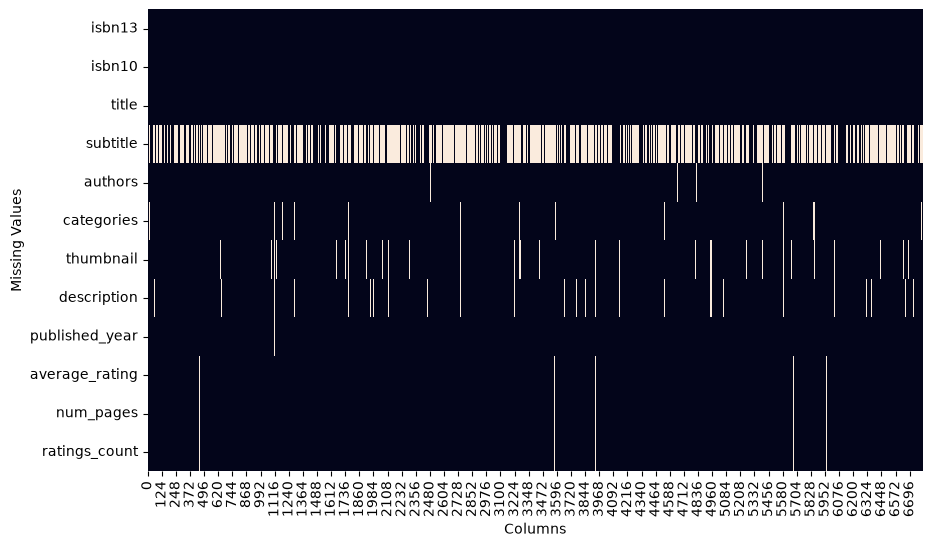

In [23]:
plt.figure(figsize=(10, 6))
ax = plt.axes()
sns.heatmap(df.isnull().transpose(), cbar=False, ax=ax)
plt.xlabel("Columns")
plt.ylabel("Missing Values")

plt.show()

In [24]:
print(df.columns)

Index(['isbn13', 'isbn10', 'title', 'subtitle', 'authors', 'categories',
       'thumbnail', 'description', 'published_year', 'average_rating',
       'num_pages', 'ratings_count'],
      dtype='str')


In [25]:
df['missing_description'] = np.where(df['description'].isnull(), 1, 0)
df['age_of_book'] = 2026 - df['published_year']

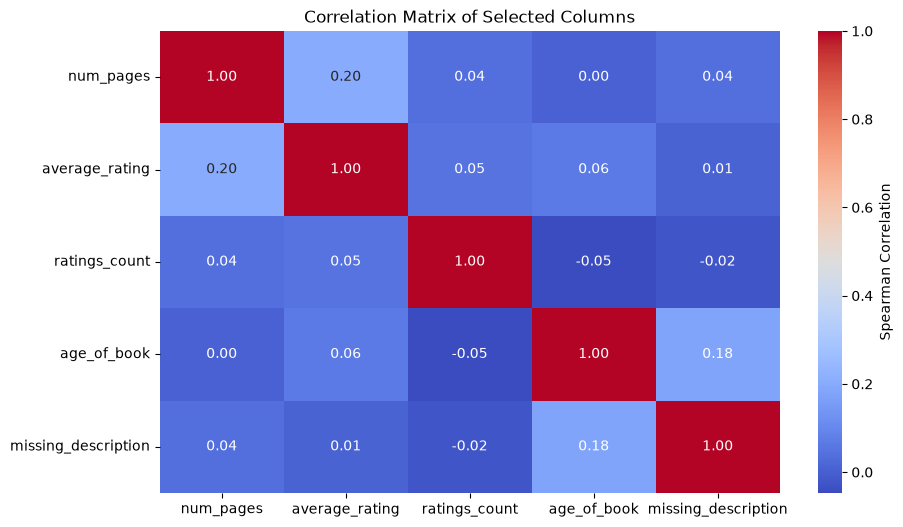

In [29]:
columns_of_interest = ['num_pages', 'average_rating', 'ratings_count', 'age_of_book', 'missing_description']

corelation_matrix = df[columns_of_interest].corr(method='pearson')

plt.figure(figsize=(10, 6))
sns.heatmap(corelation_matrix, annot=True, cmap='coolwarm', fmt=".2f", cbar_kws={'label': 'Spearman Correlation'})

heatmap_title = "Correlation Matrix of Selected Columns"
plt.title(heatmap_title)
plt.show()

In [40]:
books_missing = df[~(df['description'].isnull()) & ~(df['num_pages'].isnull()) & ~(df['average_rating'].isnull()) & ~(df['ratings_count'].isnull()) & ~(df['published_year'].isnull())]

books_missing 

,isbn13,isbn10,title,subtitle,authors,categories,thumbnail,description,published_year,average_rating,num_pages,ratings_count,missing_description,age_of_book
0,9780002005883,0002005883,Gilead,NaN,Marilynne Robinson,Fiction,http://books.google.com/books/content?id=KQZCP...,A NOVEL THAT READERS and critics have been eag...,2004.0,3.85,247.0,361.0,0,22.0
1,9780002261982,0002261987,Spider's Web,A Novel,Charles Osborne;Agatha Christie,Detective and mystery stories,http://books.google.com/books/content?id=gA5GP...,A new 'Christie for Christmas' -- a full-lengt...,2000.0,3.83,241.0,5164.0,0,26.0
2,9780006163831,0006163831,The One Tree,NaN,Stephen R. Donaldson,American fiction,http://books.google.com/books/content?id=OmQaw...,Volume Two of Stephen Donaldson's acclaimed se...,1982.0,3.97,479.0,172.0,0,44.0
3,9780006178736,0006178731,Rage of angels,NaN,Sidney Sheldon,Fiction,http://books.google.com/books/content?id=FKo2T...,"A memorable, mesmerizing heroine Jennifer -- b...",1993.0,3.93,512.0,29532.0,0,33.0
4,9780006280897,0006280897,The Four Loves,NaN,Clive Staples Lewis,Christian life,http://books.google.com/books/content?id=XhQ5X...,Lewis' work on the nature of love divides love...,2002.0,4.15,170.0,33684.0,0,24.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6803,9788173031014,8173031010,Journey to the East,NaN,Hermann Hesse,Adventure stories,http://books.google.com/books/content?id=rq6JP...,This book tells the tale of a man who goes on ...,2002.0,3.70,175.0,24.0,0,24.0
6804,9788179921623,817992162X,The Monk Who Sold His Ferrari: A Fable About F...,NaN,Robin Sharma,Health & Fitness,http://books.google.com/books/content?id=c_7mf...,"Wisdom to Create a Life of Passion, Purpose, a...",2003.0,3.82,198.0,1568.0,0,23.0
6805,9788185300535,8185300534,I Am that,Talks with Sri Nisargadatta Maharaj,Sri Nisargadatta Maharaj;Sudhakar S. Dikshit,Philosophy,http://books.google.com/books/content?id=Fv_JP...,This collection of the timeless teachings of o...,1999.0,4.51,531.0,104.0,0,27.0
6808,9789027712059,9027712050,The Berlin Phenomenology,NaN,Georg Wilhelm Friedrich Hegel,History,http://books.google.com/books/content?id=Vy7Sk...,Since the three volume edition ofHegel's Philo...,1981.0,0.00,210.0,0.0,0,45.0


In [ ]:
books_missing.describe(include='all')


,isbn13,isbn10,title,subtitle,authors,categories,thumbnail,description,published_year,average_rating,num_pages,ratings_count,missing_description,age_of_book
count,6.507000e+03,6507,6507,2281,6444,6474,6293,6507,6507.000000,6507.000000,6507.000000,6.507000e+03,6507.0,6507.000000
unique,NaN,6507,6133,1915,3629,531,6293,6434,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,0002005883,The Lord of the Rings,A Novel,Agatha Christie,Fiction,http://books.google.com/books/content?id=KQZCP...,No Marketing Blurb,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,1,10,225,37,2523,1,6,NaN,NaN,NaN,NaN,NaN,NaN
mean,9.780668e+12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1998.966498,3.932683,346.071000,2.175727e+04,0.0,27.033502
std,5.868404e+08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.837214,0.322427,233.440498,1.402505e+05,0.0,9.837214
min,9.780002e+12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1876.000000,0.000000,0.000000,0.000000e+00,0.0,7.000000
25%,9.780317e+12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1997.000000,3.770000,208.000000,1.750000e+02,0.0,21.000000
50%,9.780552e+12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2002.000000,3.950000,304.000000,1.081000e+03,0.0,24.000000
75%,9.780807e+12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2005.000000,4.130000,418.000000,6.309500e+03,0.0,29.000000


C:\Users\ncyvo\AppData\Local\Temp\ipykernel_42444\3763000437.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category_data, x='categories', y='count', palette='viridis')


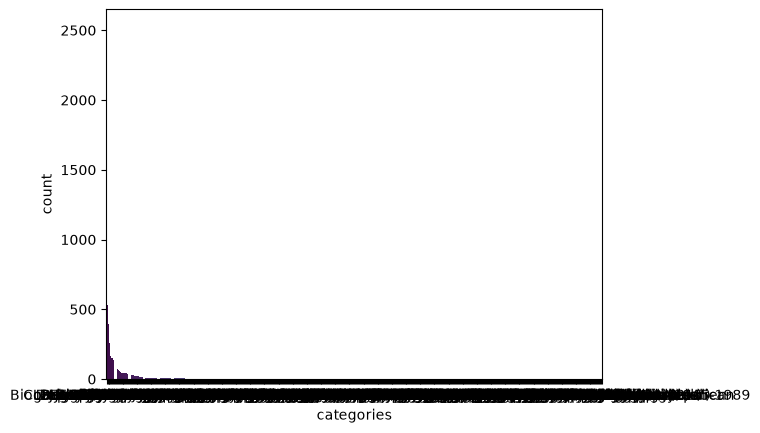

In [49]:
category_data =books_missing['categories'].value_counts().reset_index().sort_values('count', ascending=False)
sns.barplot(data=category_data, x='categories', y='count', palette='viridis')
plt.show()

In [61]:
books_missing['words_in_description'] = books_missing['description'].apply(lambda x: len(str(x).split()))

books_missing['words_in_description'].describe(include='all')


count    6507.000000
mean       66.325803
std        66.120291
min         1.000000
25%        27.000000
50%        40.000000
75%        82.000000
max       920.000000
Name: words_in_description, dtype: float64

Text(0.5, 1.0, 'Distribution of Number of Words in Book Descriptions')

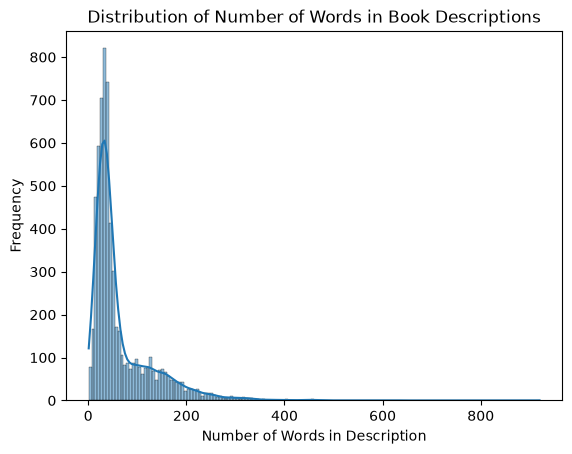

In [62]:
sns.histplot(data=books_missing, x='words_in_description', kde=True)

plt.xlabel('Number of Words in Description')
plt.ylabel('Frequency')
plt.title('Distribution of Number of Words in Book Descriptions')

In [66]:
books_missing.loc[books_missing['words_in_description'].between(1,4), ['words_in_description', 'description', 'title']].sort_values('words_in_description', ascending=True)

,words_in_description,description,title
6,1,Donation.,An Autobiography
11,1,Fantasy-roman.,Assassin's Apprentice
1346,1,Fantasy-roman.,The Treason of Isengard
1981,1,Romance.,Time & Again
2946,1,FICTION-ROMANCE/GOTHIC,The Changeling
3364,1,Fantasy-roman.,Strata
6794,1,源氏物語54帖、「宮田切り絵」の真骨頂。,ゲンジモノガタリ
6721,1,Horror.,The Value of X
5505,1,Eventyrroman.,Arrows of the Queen
5599,1,#48.,"Novels, 1936-1940"


In [67]:
books_missing.loc[books_missing['words_in_description'].between(5,14), ['words_in_description', 'description', 'title']].sort_values('words_in_description', ascending=True)

,words_in_description,description,title
6757,5,Audio Book- unabriged on CD,Think and Grow Rich: The 21st-Century Edition
682,5,Biography of John Wesley Powell.,Beyond the Hundredth Meridian
5054,5,Includes bibliographical references and index,The Anatomy Coloring Book
4293,5,Four adventures of the Chrestomanci.,The Chrestomanci Quartet
4080,5,Five stories by Douglas Adams.,The More Than Complete Hitchhiker's Guide
...,...,...,...
94,14,The title story in this collection of shorts n...,Close Range
6637,14,The Twentieth Anniversary edition of Gloria An...,Borderlands
6644,14,"Twenty-one stories include ""The Turn of the Sc...","Complete Stories, 1892-1898"
2,14,Volume Two of Stephen Donaldson's acclaimed se...,The One Tree


In [101]:
books_missing.loc[books_missing['words_in_description'].between(15,24), ['words_in_description', 'description', 'title']].sort_values('words_in_description', ascending=True)

,words_in_description,description,title
6767,15,Everything from the fingerprints of the gods t...,Underground!
475,15,A novel about the active lives of two rather d...,Heaven to Betsy
532,15,Translated by Alfred John Church and William J...,The Complete Works
603,15,An assistant police commissioner in a West Afr...,The Heart of the Matter
639,15,Suitable for introductory Social Psychology cl...,Social Psychology
...,...,...,...
392,24,This fascinating reappraisal by a rising young...,Courtesans and Fishcakes
444,24,A fact-based novel that recounts the life of n...,Ines of My Soul LP
6737,24,Discusses the essential elements in creating a...,Theory of Fun for Game Design
6748,24,Shares selections from the author's column in ...,The Polysyllabic Spree


In [80]:
books_missing.loc[books_missing['words_in_description'].between(25,34), ['words_in_description', 'description', 'title']].sort_values('words_in_description', ascending=True)

,words_in_description,description,title
6669,25,The author of Some Hope returns with a story o...,Mother's Milk
404,25,"Gurgeh, a champion game player, travels a hund...",The Player of Games
6457,25,"The newly crowned queen of the undead, fashion...",Undead and Unappreciated
471,25,A beautiful gift edition of Thomas Bulfinch's ...,Bulfinch's Mythology
4963,25,Gathers the Nobel Prize winning poet and drama...,"The Complete Short Prose, 1929-1989"
...,...,...,...
5137,34,"One of the late Shusaku Endo's finest works, T...",The Samurai
5116,34,More than four hundred rarely seen black-and-w...,The Beatles
5077,34,"In a future world, scientists predict criminal...",The Minority Report
5059,34,This revised edition of Feynman’s legendary le...,The Feynman Lectures on Physics


In [87]:
books_missing_25_words = books_missing[books_missing['words_in_description'] >= 25]


In [88]:
books_missing_25_words['title_and_subtitle'] = (
    
    np.where(books_missing_25_words['subtitle'].isnull(), books_missing_25_words['title'], books_missing_25_words['title'] + ": " + books_missing_25_words['subtitle'])
)

In [89]:
books_missing_25_words

,isbn13,isbn10,title,subtitle,authors,categories,thumbnail,description,published_year,average_rating,num_pages,ratings_count,missing_description,age_of_book,words_in_description,title_and_subtitle
0,9780002005883,0002005883,Gilead,NaN,Marilynne Robinson,Fiction,http://books.google.com/books/content?id=KQZCP...,A NOVEL THAT READERS and critics have been eag...,2004.0,3.85,247.0,361.0,0,22.0,199,Gilead
1,9780002261982,0002261987,Spider's Web,A Novel,Charles Osborne;Agatha Christie,Detective and mystery stories,http://books.google.com/books/content?id=gA5GP...,A new 'Christie for Christmas' -- a full-lengt...,2000.0,3.83,241.0,5164.0,0,26.0,205,Spider's Web: A Novel
3,9780006178736,0006178731,Rage of angels,NaN,Sidney Sheldon,Fiction,http://books.google.com/books/content?id=FKo2T...,"A memorable, mesmerizing heroine Jennifer -- b...",1993.0,3.93,512.0,29532.0,0,33.0,57,Rage of angels
4,9780006280897,0006280897,The Four Loves,NaN,Clive Staples Lewis,Christian life,http://books.google.com/books/content?id=XhQ5X...,Lewis' work on the nature of love divides love...,2002.0,4.15,170.0,33684.0,0,24.0,45,The Four Loves
5,9780006280934,0006280935,The Problem of Pain,NaN,Clive Staples Lewis,Christian life,http://books.google.com/books/content?id=Kk-uV...,"""In The Problem of Pain, C.S. Lewis, one of th...",2002.0,4.09,176.0,37569.0,0,24.0,75,The Problem of Pain
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6802,9788172235222,8172235224,Mistaken Identity,NaN,Nayantara Sahgal,Indic fiction (English),http://books.google.com/books/content?id=q-tKP...,On A Train Journey Home To North India After L...,2003.0,2.93,324.0,0.0,0,23.0,288,Mistaken Identity
6803,9788173031014,8173031010,Journey to the East,NaN,Hermann Hesse,Adventure stories,http://books.google.com/books/content?id=rq6JP...,This book tells the tale of a man who goes on ...,2002.0,3.70,175.0,24.0,0,24.0,63,Journey to the East
6804,9788179921623,817992162X,The Monk Who Sold His Ferrari: A Fable About F...,NaN,Robin Sharma,Health & Fitness,http://books.google.com/books/content?id=c_7mf...,"Wisdom to Create a Life of Passion, Purpose, a...",2003.0,3.82,198.0,1568.0,0,23.0,117,The Monk Who Sold His Ferrari: A Fable About F...
6805,9788185300535,8185300534,I Am that,Talks with Sri Nisargadatta Maharaj,Sri Nisargadatta Maharaj;Sudhakar S. Dikshit,Philosophy,http://books.google.com/books/content?id=Fv_JP...,This collection of the timeless teachings of o...,1999.0,4.51,531.0,104.0,0,27.0,174,I Am that: Talks with Sri Nisargadatta Maharaj


In [90]:
books_missing_25_words.isnull().sum()

isbn13                     0
isbn10                     0
title                      0
subtitle                3380
authors                   32
categories                30
thumbnail                166
description                0
published_year             0
average_rating             0
num_pages                  0
ratings_count              0
missing_description        0
age_of_book                0
words_in_description       0
title_and_subtitle         0
dtype: int64

In [105]:
books_missing_25_words['tagged_description'] = books_missing_25_words[['isbn13','description']].astype(str).agg(' '.join, axis=1)

In [107]:
books_missing_25_words['tagged_description'].iloc[0]


'9780002005883 A NOVEL THAT READERS and critics have been eagerly anticipating for over a decade, Gilead is an astonishingly imagined story of remarkable lives. John Ames is a preacher, the son of a preacher and the grandson (both maternal and paternal) of preachers. It’s 1956 in Gilead, Iowa, towards the end of the Reverend Ames’s life, and he is absorbed in recording his family’s story, a legacy for the young son he will never see grow up. Haunted by his grandfather’s presence, John tells of the rift between his grandfather and his father: the elder, an angry visionary who fought for the abolitionist cause, and his son, an ardent pacifist. He is troubled, too, by his prodigal namesake, Jack (John Ames) Boughton, his best friend’s lost son who returns to Gilead searching for forgiveness and redemption. Told in John Ames’s joyous, rambling voice that finds beauty, humour and truth in the smallest of life’s details, Gilead is a song of celebration and acceptance of the best and the wors

In [108]:
(
    books_missing_25_words
    .drop(['subtitle', 'missing_description', 'age_of_book', 'words_in_description'], axis=1)
    .to_csv("../data/processed/books_cleaned.csv", index=False)
)